**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 2**
Pandas para el análisis de datos en Python

---

*   NOMBRE: **VANESSA ESTOPIER TINAJERO**
*   MATRÍCULA: **A01841600**

---

En esta actividad trabajarás con el archivo `cleaned_weather.csv`, un extracto del conjunto de datos meteorológicos a lo largo de todo el año 2020 en una estación del Instituto *Max Planck* (Alemania) disponible en Kaggle.

Los datos meteorológicos fueron registrados cada 10 minutos e incluyen los siguientes indicadores:

*   `timestamp`: Fecha y hora de la observación.
*   `p`: Presión atmosférica en milibares (mbar)
*   `T`: Temperatura del aire en grados Celsius (°C)
*   `Tpot`: Temperatura potencial en Kelvin (K)
*   `rh`: Humedad relativa en porcentaje (%)
*   `VPact`: Presión real de vapor en milibares (mbar)
*   `sh`: Humedad específica en gramos por kilogramo (g/kg)
*   `H2OC`: Concentración de vapor de agua en milimoles por mol (mmol/mol) de aire seco
*   `rho`: Densidad del aire en gramos por metro cúbico (g/m³)
*   `wv`: Velocidad del viento en metros por segundo (m/s)
*   `wd`: Dirección del viento en grados (°)
*   `rain`: Precipitación total en milímetros (mm)
*   `raining`: Duración de la lluvia en segundos (s)

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importa las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Evita que aparezcan warnings en la libreta (se revisó que no afectan los resultados)
import warnings
warnings.filterwarnings('ignore')

# Opciones de despliegue para ver todas las columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

1.	Descarga el archivo: `cleaned_weather.csv` y guarda, en un dataframe (`weather_df`), todos sus registros.
- Determina la dimensionalidad del dataframe y obtén los identificadores de columnas.
- Renombra las columnas para facilitar la interpretación de los indicadores en los ejercicios siguientes:
  - `medicion, presion_atmosferica, temperatura_celsius, temperatura_kelvin, humedad_relativa, presion_vapor, humedad_especifica, concentracion_vapor, densidad_aire, velocidad_viento, direccion_viento, precipitacion_total, duracion_lluvia`
- Muestra los primeros y los últimos 5 registros.
- ¿Hay valores faltantes en el dataframe?

In [2]:
# Carga del archivo en el dataframe weather_df
weather_df = pd.read_csv('cleaned_weather.csv')

# Dimensionalidad: (número de filas, número de columnas)
print("Dimensionalidad del dataframe:", weather_df.shape)

# Identificadores (nombres) de las columnas originales
print("Columnas originales:", weather_df.columns.tolist())

Dimensionalidad del dataframe: (52696, 13)
Columnas originales: ['timestamp', 'p', 'T', 'Tpot', 'rh', 'VPact', 'sh', 'H2OC', 'rho', 'wv', 'wd', 'rain', 'raining']


In [3]:
# Renombrado de columnas. El orden de esta lista corresponde al orden
# de las columnas originales impreso en la celda anterior.
weather_df.columns = ['medicion', 'presion_atmosferica', 'temperatura_celsius',
                      'temperatura_kelvin', 'humedad_relativa', 'presion_vapor',
                      'humedad_especifica', 'concentracion_vapor', 'densidad_aire',
                      'velocidad_viento', 'direccion_viento', 'precipitacion_total',
                      'duracion_lluvia']

weather_df.columns

Index(['medicion', 'presion_atmosferica', 'temperatura_celsius', 'temperatura_kelvin', 'humedad_relativa', 'presion_vapor', 'humedad_especifica',
       'concentracion_vapor', 'densidad_aire', 'velocidad_viento', 'direccion_viento', 'precipitacion_total', 'duracion_lluvia'],
      dtype='object')

In [4]:
# Primeros 5 registros
display(weather_df.head())

# Últimos 5 registros
display(weather_df.tail())

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
0,01/01/20 0:10,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0
1,01/01/20 0:20,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0
2,01/01/20 0:30,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0
3,01/01/20 0:40,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0
4,01/01/20 0:50,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0


,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
52691,31/12/20 23:20,978.32,2.28,277.16,80.0,5.76,3.67,5.89,1234.61,0.73,180.6,0.0,0
52692,31/12/20 23:30,978.30,2.13,277.01,83.1,5.92,3.77,6.05,1235.20,0.43,174.0,0.0,0
52693,31/12/20 23:40,978.26,1.99,276.88,82.2,5.80,3.69,5.93,1235.82,0.38,248.9,0.0,0
52694,31/12/20 23:50,978.26,2.07,276.95,81.4,5.77,3.68,5.90,1235.49,0.57,196.6,0.0,0
52695,01/01/21 0:00,978.24,2.01,276.89,82.4,5.82,3.71,5.95,1235.71,0.57,221.3,0.0,0


In [5]:
# Conteo de valores faltantes por columna
print("Total de valores faltantes en el dataframe:", weather_df.isna().sum().sum())
weather_df.isna().sum()

Total de valores faltantes en el dataframe: 0


,0
medicion,0
presion_atmosferica,0
temperatura_celsius,0
temperatura_kelvin,0
humedad_relativa,0
presion_vapor,0
humedad_especifica,0
concentracion_vapor,0
densidad_aire,0
velocidad_viento,0


**Análisis:**

El dataframe `weather_df` tiene una dimensionalidad de **52,696 filas y 13 columnas**. Las columnas fueron renombradas a nombres descriptivos en español para facilitar la interpretación de los indicadores en los ejercicios posteriores.

Al revisar los primeros registros se observa que la serie inicia el **01/01/20 a las 00:10** y, en los últimos registros, termina el **01/01/21 a las 00:00**, lo que anticipa que existe al menos un registro que no pertenece al año 2020.

**¿Hay valores faltantes?** No. El conteo con `isna().sum()` arroja **cero valores faltantes (NaN)** en todas las columnas del dataframe.

2. Determina el tipo de datos que tienen las columnas.
- Cambia la columna `medicion` a datetime utilizando el formato: `%d/%m/%y %H:%M`
- Obtén dos columnas adicionales separando `medicion` en `fecha` y `hora`

In [6]:
# Tipo de datos de cada columna
weather_df.dtypes

,0
medicion,object
presion_atmosferica,float64
temperatura_celsius,float64
temperatura_kelvin,float64
humedad_relativa,float64
presion_vapor,float64
humedad_especifica,float64
concentracion_vapor,float64
densidad_aire,float64
velocidad_viento,float64


In [7]:
# Conversión de la columna medicion al tipo datetime.
# Se usa %y (minúscula) porque el año viene expresado con dos dígitos (ej. 01/01/20).
weather_df['medicion'] = pd.to_datetime(weather_df['medicion'], format='%d/%m/%y %H:%M')

# Separación de medicion en dos columnas nuevas: fecha y hora
weather_df['fecha'] = weather_df['medicion'].dt.date
weather_df['hora']  = weather_df['medicion'].dt.time

print(weather_df.dtypes)
weather_df.head()

medicion               datetime64[ns]
presion_atmosferica           float64
temperatura_celsius           float64
temperatura_kelvin            float64
humedad_relativa              float64
presion_vapor                 float64
humedad_especifica            float64
concentracion_vapor           float64
densidad_aire                 float64
velocidad_viento              float64
direccion_viento              float64
precipitacion_total           float64
duracion_lluvia                 int64
fecha                          object
hora                           object
dtype: object


,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
0,2020-01-01 00:10:00,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0,2020-01-01,00:10:00
1,2020-01-01 00:20:00,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0,2020-01-01,00:20:00
2,2020-01-01 00:30:00,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0,2020-01-01,00:30:00
3,2020-01-01 00:40:00,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0,2020-01-01,00:40:00
4,2020-01-01 00:50:00,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0,2020-01-01,00:50:00


**Análisis:**

Originalmente la columna `medicion` era de tipo **`object`** (es decir, texto), por lo que no permitía realizar operaciones cronológicas. La columna `duracion_lluvia` es de tipo **`int64`** y las once columnas restantes son de tipo **`float64`**.

Tras aplicar `pd.to_datetime()` con el formato `%d/%m/%y %H:%M`, la columna `medicion` queda como **`datetime64[ns]`**. Esto habilita el uso del accesor `.dt`, con el que se generaron las columnas `fecha` y `hora`, necesarias para los agrupamientos de los ejercicios siguientes.

3. Determina la cantidad de valores únicos de cada columna.
- La columna `medicion` tiene un valor menos que el número total de filas del dataframe, lo que indica que hay una fecha duplicada. Identifica cuál es.
- Comprueba si las demás columnas también contienen los mismos valores; si es así, elimina  uno de los registros duplicados.

In [8]:
# Cantidad de valores únicos por columna
print("Número total de filas:", len(weather_df))
weather_df.nunique()

Número total de filas: 52696


,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [9]:
# Identificación de la medición duplicada.
# keep=False marca como duplicadas TODAS las apariciones, no solo la segunda.
duplicadas = weather_df[weather_df['medicion'].duplicated(keep=False)]
duplicadas

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
19043,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00
19044,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00


In [10]:
# Comprobación: ¿las demás columnas también coinciden?
# duplicated() sin argumentos compara la fila completa.
print("Filas completamente duplicadas:", weather_df.duplicated().sum())

Filas completamente duplicadas: 1


In [11]:
# Al tratarse de un registro idéntico en todas sus columnas, se elimina una de las dos apariciones
weather_df = weather_df.drop_duplicates().reset_index(drop=True)

print("Dimensionalidad tras eliminar el duplicado:", weather_df.shape)

Dimensionalidad tras eliminar el duplicado: (52695, 15)


**Análisis:**

La columna `medicion` presenta **52,695 valores únicos** frente a **52,696 filas**, lo que confirma la existencia de una marca de tiempo repetida. El registro duplicado corresponde al **12 de mayo de 2020 a las 06:00 horas**.

Al comparar las dos filas se comprueba que **son idénticas en todas las columnas**, lo cual se verifica con `weather_df.duplicated().sum()`, que devuelve **1**. Esto descarta que se trate de dos observaciones distintas registradas con el mismo sello de tiempo y permite concluir que es un error de duplicación en la captura.

Por lo anterior, se elimina una de las dos apariciones con `drop_duplicates()`, quedando el dataframe con **52,695 filas**.

4. Imprime nuevamente las cantidad de valores únicos por columna.
- ¿Por qué son 144 horas diferentes?
- La cantidad de combinaciones únicas de fecha y hora no coincide con el número total de mediciones. Aunque no haya valores NaN, esto no garantiza que no se hayan omitido registros. Identifica las fechas en las que faltan mediciones.
- Una vez concluido el análisis de mediciones faltantes, elimina todos los registros que no correspondan al año 2020 y la columna `medicion`.

In [12]:
# Valores únicos por columna después de eliminar el duplicado
print("Número total de filas:", len(weather_df))
weather_df.nunique()

Número total de filas: 52695


,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [13]:
# Número de mediciones registradas por fecha (lo esperado son 144 por día)
conteo_por_fecha = weather_df.groupby('fecha').size()

# Fechas que NO tienen las 144 mediciones esperadas
fechas_incompletas = conteo_por_fecha[conteo_por_fecha != 144]
print("Fechas con un número de mediciones distinto a 144:")
print(fechas_incompletas)

Fechas con un número de mediciones distinto a 144:
fecha
2020-01-01    143
2020-05-29    135
2021-01-01      1
dtype: int64


In [14]:
# Identificación puntual de las marcas de tiempo ausentes durante 2020.
# Se construye la secuencia teórica completa cada 10 minutos y se compara con la real.
rango_completo = pd.date_range(start='2020-01-01 00:00',
                               end='2020-12-31 23:50',
                               freq='10min')

faltantes = rango_completo.difference(weather_df['medicion'])

print("Mediciones esperadas en 2020:", len(rango_completo))
print("Mediciones faltantes:", len(faltantes))
print()
print("Marcas de tiempo ausentes:")
for f in faltantes:
    print(" ", f)

Mediciones esperadas en 2020: 52704
Mediciones faltantes: 10

Marcas de tiempo ausentes:
  2020-01-01 00:00:00
  2020-05-29 09:40:00
  2020-05-29 09:50:00
  2020-05-29 10:00:00
  2020-05-29 10:10:00
  2020-05-29 10:20:00
  2020-05-29 10:30:00
  2020-05-29 10:40:00
  2020-05-29 10:50:00
  2020-05-29 11:00:00


In [15]:
# Se conservan únicamente los registros del año 2020
weather_df = weather_df[weather_df['medicion'].dt.year == 2020]

# Se elimina la columna medicion, ya que la información quedó desglosada en fecha y hora
weather_df = weather_df.drop(columns=['medicion']).reset_index(drop=True)

print("Dimensionalidad final:", weather_df.shape)
weather_df.head()

Dimensionalidad final: (52694, 14)


,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
0,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0,2020-01-01,00:10:00
1,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0,2020-01-01,00:20:00
2,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0,2020-01-01,00:30:00
3,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0,2020-01-01,00:40:00
4,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0,2020-01-01,00:50:00


**Análisis:**

**¿Por qué son 144 horas diferentes?**

Porque las observaciones se registran **cada 10 minutos**. En una hora caben 6 mediciones y en un día 24 horas, de modo que existen 6 × 24 = **144 marcas de tiempo distintas dentro de un mismo día** (00:00, 00:10, 00:20, …, 23:50). Estas 144 horas se repiten idénticas día tras día, por lo que la columna `hora` solo puede tomar 144 valores únicos independientemente de cuántos días abarque la serie.

**Fechas con mediciones omitidas**

El año 2020 fue bisiesto (366 días), por lo que deberían existir 366 × 144 = **52,704 mediciones**. Sin embargo, solo se cuenta con 52,694 registros de ese año, es decir, **faltan 10 mediciones**:

| Fecha | Mediciones registradas | Mediciones faltantes |
|---|---|---|
| 2020-01-01 | 143 | 1 (la correspondiente a las 00:00) |
| 2020-05-29 | 135 | 9 (de las 09:40 a las 11:00) |

En el primer caso, el archivo simplemente inicia a las 00:10, por lo que la omisión es de frontera. En el segundo caso se trata de **nueve mediciones consecutivas**, lo que sugiere una interrupción de la estación meteorológica de aproximadamente hora y media, y no un error aleatorio de captura.

Este ejercicio confirma que la ausencia de valores `NaN` **no garantiza la integridad de una serie de tiempo**: los registros omitidos no aparecen como celdas vacías, sino como filas inexistentes, y solo se detectan comparando contra la secuencia temporal teórica.

**Depuración final**

Se eliminó el registro del **01/01/2021 00:00** por quedar fuera del año de estudio y se descartó la columna `medicion`, cuya información ya está contenida en `fecha` y `hora`. El dataframe queda con **52,694 filas y 14 columnas**.

5. Obtén un dataframe `indicadores_diarios` que sólo almacene el mayor valor de las mediciones por fecha para responder:
- ¿Cuál fue la máxima precipitación y a qué fecha pertenece?
- ¿Cuáles fueron los tres días con las velocidades de viento más altas registradas?
- ¿Cuántos días rebasaron el 90% de humedad relativa y los 30° celsius?

In [16]:
# Se agrupa por fecha y se conserva el valor máximo de cada indicador.
# numeric_only=True excluye la columna 'hora', que no es numérica.
indicadores_diarios = weather_df.groupby('fecha').max(numeric_only=True)

print("Dimensionalidad de indicadores_diarios:", indicadores_diarios.shape)
indicadores_diarios.head()

Dimensionalidad de indicadores_diarios: (366, 12)


,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
fecha,,,,,,,,,,,,
2020-01-01,1008.89,4.58,277.27,95.0,5.81,3.60,5.77,1298.02,1.91,356.9,0.0,0
2020-01-02,1004.16,6.47,279.72,93.9,5.57,3.48,5.58,1304.37,2.67,358.8,0.0,0
2020-01-03,998.45,8.17,281.80,89.3,9.34,5.86,9.39,1266.97,8.79,336.5,0.2,470
2020-01-04,1003.47,6.61,280.15,91.4,8.54,5.36,8.58,1270.10,4.61,354.7,1.0,600
2020-01-05,1009.07,4.43,277.01,85.3,6.44,3.99,6.40,1275.47,3.14,274.6,0.0,0


In [17]:
# ¿Cuál fue la máxima precipitación y a qué fecha pertenece?
max_precipitacion = indicadores_diarios['precipitacion_total'].max()
fecha_max_precipitacion = indicadores_diarios['precipitacion_total'].idxmax()

print("Máxima precipitación registrada:", max_precipitacion, "mm")
print("Fecha en que ocurrió:", fecha_max_precipitacion)

Máxima precipitación registrada: 11.2 mm
Fecha en que ocurrió: 2020-06-16


In [18]:
# ¿Cuáles fueron los tres días con las velocidades de viento más altas?
indicadores_diarios['velocidad_viento'].nlargest(3)

,velocidad_viento
fecha,
2020-02-10,13.77
2020-02-16,13.00
2020-02-09,12.52


In [19]:
# ¿Cuántos días rebasaron el 90% de humedad relativa y los 30 °C?
# Se construye una máscara booleana que combina ambas condiciones con el operador &.
BM = (indicadores_diarios['humedad_relativa'] > 90) & (indicadores_diarios['temperatura_celsius'] > 30)

print("Días que rebasaron ambos umbrales:", BM.sum())
indicadores_diarios[BM][['humedad_relativa', 'temperatura_celsius']]

Días que rebasaron ambos umbrales: 5


,humedad_relativa,temperatura_celsius
fecha,,
2020-08-11,93.8,31.42
2020-08-12,94.4,32.26
2020-08-20,97.1,30.38
2020-08-21,94.7,34.56
2020-09-15,99.9,30.16


**Análisis:**

El dataframe `indicadores_diarios` resume las 52,694 mediciones en **366 filas** (una por día del año) y 12 columnas, conservando el valor máximo diario de cada indicador.

**Máxima precipitación:** **11.2 mm**, registrada el **16 de junio de 2020**.

**Tres días con mayor velocidad de viento:**

| Fecha | Velocidad máxima (m/s) |
|---|---|
| 2020-02-10 | 13.77 |
| 2020-02-16 | 13.00 |
| 2020-02-09 | 12.52 |

Los tres días corresponden a **febrero**, lo cual es consistente con la temporada de tormentas invernales del centro de Europa.

**Días que rebasaron 90% de humedad relativa y 30 °C:** **5 días**, concentrados en el verano (11, 12, 20 y 21 de agosto, y 15 de septiembre).

Es importante señalar una precisión metodológica: como el dataframe almacena el **máximo diario de cada columna de forma independiente**, la humedad máxima y la temperatura máxima de un mismo día **no necesariamente ocurrieron en el mismo instante**. Por lo tanto, el resultado debe leerse como "días en los que se alcanzó, en algún momento, más de 90% de humedad y, en algún momento, más de 30 °C", y no como días con ambas condiciones simultáneas.

6. La función `describe()` resume múltiples estadísticas descriptivas. Utiliza esta función para explorar y responder las preguntas sobre las variables en el dataframe de `indicadores_diarios `:
- ¿Cuál es la desviación estándar de la concentración de vapor y qué indica?
- ¿Cuál es la mediana de la presión atmosférica y qué significa?
- ¿Cuál es el tercer cuartil de la duración de la lluvia y cómo se interpreta?

In [20]:
# Estadísticas descriptivas de todas las variables
indicadores_diarios.describe()

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,992.977842,15.343770,289.431667,90.886530,11.409454,7.214016,11.539180,1232.622814,5.245164,317.673689,0.314208,240.382514
std,8.543447,7.850339,7.942175,9.201588,4.507555,2.872647,4.573267,32.702446,2.097012,50.611324,0.979721,273.840002
min,959.900000,-0.120000,273.460000,55.440000,3.320000,2.050000,3.290000,1167.050000,1.570000,69.570000,0.000000,0.000000
25%,988.015000,8.840000,282.732500,85.400000,7.647500,4.832500,7.742500,1207.590000,3.662500,279.075000,0.000000,0.000000
50%,993.300000,15.060000,289.160000,93.250000,10.715000,6.705000,10.735000,1231.455000,4.880000,346.650000,0.000000,0.000000
75%,998.432500,21.695000,295.957500,99.900000,14.462500,9.180000,14.685000,1256.057500,6.495000,357.300000,0.200000,600.000000
max,1020.070000,34.800000,309.130000,100.000000,24.160000,15.400000,24.530000,1318.520000,13.770000,360.000000,11.200000,600.000000


In [21]:
# Valores puntuales solicitados
print("Desviación estándar de concentracion_vapor:",
      round(indicadores_diarios['concentracion_vapor'].std(), 2), "mmol/mol")
print("Mediana de presion_atmosferica:",
      round(indicadores_diarios['presion_atmosferica'].median(), 2), "mbar")
print("Tercer cuartil de duracion_lluvia:",
      round(indicadores_diarios['duracion_lluvia'].quantile(0.75), 2), "s")

Desviación estándar de concentracion_vapor: 4.57 mmol/mol
Mediana de presion_atmosferica: 993.3 mbar
Tercer cuartil de duracion_lluvia: 600.0 s


**Análisis:**

**Desviación estándar de la concentración de vapor: 4.57 mmol/mol**

La desviación estándar mide la dispersión de los datos respecto a su media. Con una media de 11.54 mmol/mol, esta desviación representa aproximadamente el **40% del valor promedio**, lo que indica una **dispersión alta**. Esto es coherente con el comportamiento estacional del vapor de agua: el rango observado va de 3.29 a 24.53 mmol/mol, reflejando aire muy seco durante el invierno y notablemente húmedo durante el verano.

**Mediana de la presión atmosférica: 993.30 mbar**

La mediana es el valor que divide al conjunto en dos mitades iguales: **el 50% de los días tuvo una presión máxima inferior o igual a 993.30 mbar y el otro 50% superior**. A diferencia de la media, no se ve afectada por valores extremos. En este caso, la mediana (993.30) y la media (992.98) son prácticamente idénticas, lo que sugiere una **distribución simétrica** y sin valores atípicos dominantes.

**Tercer cuartil de la duración de la lluvia: 600 s**

El tercer cuartil indica que **el 75% de los días registró una duración máxima de lluvia menor o igual a 600 segundos**. Este resultado requiere una lectura cuidadosa: como las mediciones se toman en intervalos de 10 minutos, **600 segundos es el valor máximo posible** dentro de un intervalo. Que el percentil 75 coincida con el tope significa que en **al menos el 25% de los días llovió de manera continua durante un intervalo completo**.

Al mismo tiempo, la mediana de esta variable es **0 segundos**, lo que revela que **más de la mitad de los días del año no registró lluvia alguna**. La variable presenta, por tanto, una distribución fuertemente sesgada y concentrada en sus dos extremos.

7.	Dibuja un histograma para cada una de las columnas de `indicadores_diarios`.

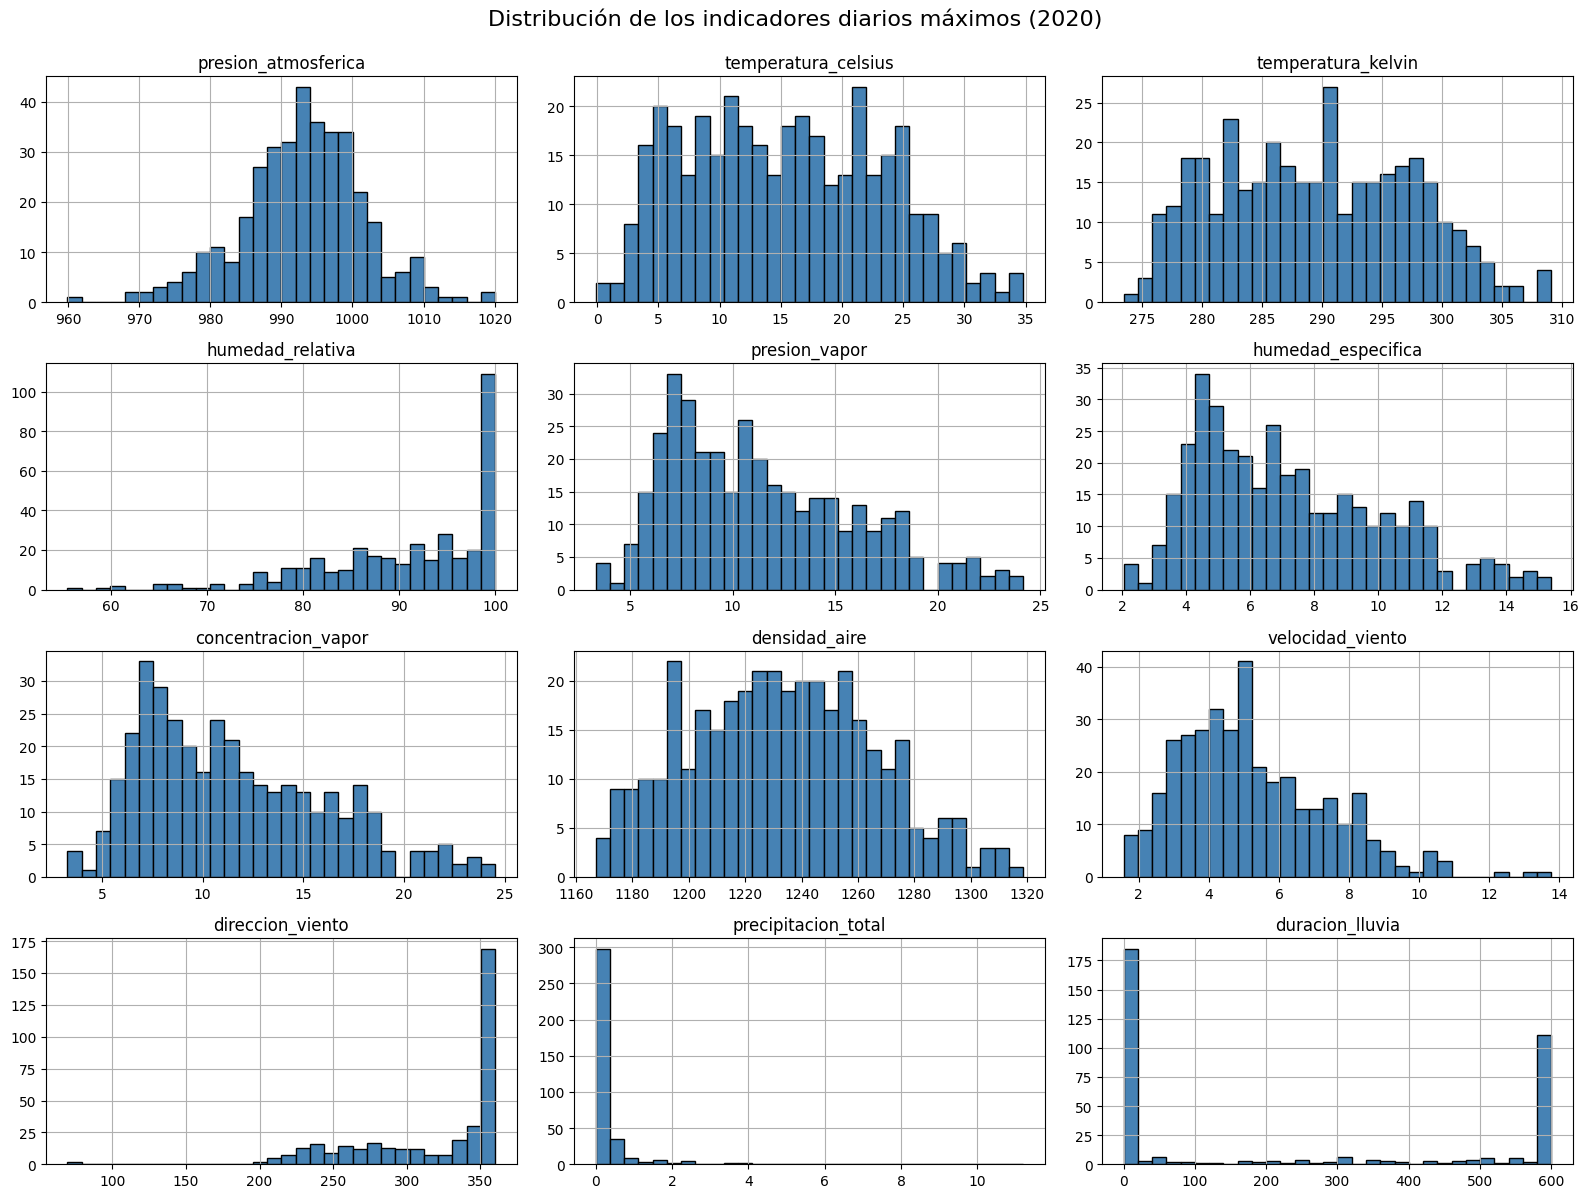

In [22]:
# Histograma de cada una de las columnas de indicadores_diarios.
# Se usa una cuadrícula de 4x3 para visualizar las 12 variables de forma compacta.
indicadores_diarios.hist(figsize=(16, 12), bins=30, edgecolor='black', color='steelblue')

plt.suptitle('Distribución de los indicadores diarios máximos (2020)', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()

**Análisis:**

Los histogramas permiten identificar el comportamiento de cada variable:

- **`temperatura_celsius` y `temperatura_kelvin`** presentan una distribución **relativamente plana**, con los días repartidos de forma bastante uniforme a lo largo del rango anual y una caída marcada por encima de los 30 °C. Esto refleja el clima templado de la región: no predomina un rango térmico en particular, sino que el año transita de manera gradual entre el invierno y el verano.

- **`presion_vapor`, `humedad_especifica` y `concentracion_vapor`** muestran distribuciones **sesgadas a la derecha**, con la mayor concentración de días en valores bajos o intermedios. Esto responde al ciclo estacional del vapor de agua: el aire permanece seco la mayor parte del año y solo unos pocos días de verano alcanzan los valores más altos.

- **`presion_atmosferica` y `densidad_aire`** muestran distribuciones **aproximadamente simétricas**, cercanas a una forma acampanada, lo que confirma lo observado en el ejercicio anterior sobre la similitud entre su media y su mediana.

- **`humedad_relativa`** está **fuertemente sesgada a la izquierda** y acumulada cerca del 100%. Esto es esperable, ya que se trata del máximo diario y en casi todos los días se alcanza la saturación en algún momento, típicamente durante la madrugada.

- **`precipitacion_total` y `duracion_lluvia`** exhiben una concentración extrema en cero, confirmando que la mayoría de los días no registró lluvia. `duracion_lluvia` presenta además una acumulación visible en 600 s, su valor máximo posible, lo que produce una **distribución bimodal en los extremos**.

- **`velocidad_viento`** se concentra en valores bajos con una cola hacia la derecha, correspondiente a los episodios de tormenta invernal identificados en el ejercicio 5.

- **`direccion_viento`** no debe interpretarse como las demás: al ser una **variable circular** medida en grados (0° y 360° representan la misma dirección), su histograma no refleja adecuadamente la distribución real de las direcciones predominantes.

8. Utiliza el dataframe de indicadores diarios para crear un nuevo dataframe `indicadores_mensuales`. Para ello:
- Crea una nueva columna `mes` a partir de la fecha que se encuentra en el índice.
- Haciendo uso de `groupby()`, calcula los promedios mensuales y conserva únicamente las columnas `humedad_relativa`, `temperatura_celsius` y `velocidad_viento` en el nuevo dataframe.

In [23]:
# El índice de indicadores_diarios contiene objetos de tipo date.
# Se convierte a DatetimeIndex para poder extraer el mes con el accesor .month
indicadores_diarios.index = pd.to_datetime(indicadores_diarios.index)
indicadores_diarios.index.name = 'fecha'

# Nueva columna mes a partir de la fecha del índice
indicadores_diarios['mes'] = indicadores_diarios.index.month

indicadores_diarios[['mes']].head()

,mes
fecha,
2020-01-01,1
2020-01-02,1
2020-01-03,1
2020-01-04,1
2020-01-05,1


In [24]:
# Promedios mensuales conservando únicamente las tres columnas solicitadas
indicadores_mensuales = indicadores_diarios.groupby('mes')[['humedad_relativa',
                                                            'temperatura_celsius',
                                                            'velocidad_viento']].mean()

indicadores_mensuales

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


**Análisis:**

El dataframe `indicadores_mensuales` resume los 366 registros diarios en **12 filas**, una por mes, con el promedio de los máximos diarios de cada indicador.

Los resultados reproducen con claridad el ciclo anual de una estación en Alemania:

- La **temperatura** describe una curva estacional nítida, con su mínimo en **diciembre (5.68 °C)** y **enero (6.82 °C)**, y su máximo en **agosto (26.10 °C)**, seguido de julio (24.34 °C).
- La **humedad relativa** sigue el patrón inverso, con sus valores más bajos en **abril (80.94%)** y los más altos entre **septiembre y diciembre (por encima del 96.9%)**, propios del otoño e invierno europeos.
- La **velocidad del viento** alcanza su punto más alto en **febrero (7.49 m/s)**, consistente con los días de mayor viento identificados en el ejercicio 5, y su valor mínimo en **septiembre (4.15 m/s)**.

9. Construye el mismo dataframe mensual, pero esta vez utilizando la función `pivot_table()`.
- Añade la columna `indice_calor` usando la fórmula de Thom (*Temperature - Humidity Index*, TDI):
> `temperatura_celsius + 0.33 x humedad_relativa - 0.7 x velocidad_viento - 4`

In [25]:
# Mismo resultado usando pivot_table().
# index = variable de agrupación, values = columnas a resumir, aggfunc = función de agregación.
indicadores_mensuales_pivot = pd.pivot_table(indicadores_diarios,
                                             index='mes',
                                             values=['humedad_relativa',
                                                     'temperatura_celsius',
                                                     'velocidad_viento'],
                                             aggfunc='mean')

# pivot_table ordena las columnas alfabéticamente; se reordenan para igualar al ejercicio anterior
indicadores_mensuales_pivot = indicadores_mensuales_pivot[['humedad_relativa',
                                                           'temperatura_celsius',
                                                           'velocidad_viento']]

indicadores_mensuales_pivot

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


In [26]:
# Verificación de que ambos métodos producen exactamente el mismo resultado
print("¿Los dataframes son idénticos?",
      indicadores_mensuales.equals(indicadores_mensuales_pivot))

¿Los dataframes son idénticos? True


In [27]:
# Cálculo del índice de calor con la fórmula de Thom (THI)
indicadores_mensuales_pivot['indice_calor'] = (
      indicadores_mensuales_pivot['temperatura_celsius']
    + 0.33 * indicadores_mensuales_pivot['humedad_relativa']
    - 0.70 * indicadores_mensuales_pivot['velocidad_viento']
    - 4
)

indicadores_mensuales_pivot.round(2)

,humedad_relativa,temperatura_celsius,velocidad_viento,indice_calor
mes,,,,
1,89.78,6.82,5.03,28.93
2,85.72,8.96,7.49,28.01
3,85.37,9.68,6.42,29.36
4,80.94,16.88,5.00,36.09
5,87.46,17.14,4.87,38.59
6,94.26,22.21,5.30,45.61
7,85.96,24.34,4.83,45.32
8,92.00,26.10,5.04,48.93
9,97.57,21.57,4.15,46.86


**Análisis:**

`pivot_table()` produce **exactamente el mismo resultado** que `groupby()`, lo cual se verificó con el método `.equals()`. La diferencia entre ambos enfoques es de estilo y flexibilidad:

- **`groupby()`** sigue una lógica de *dividir–aplicar–combinar* y resulta más directo cuando se desea encadenar operaciones o aplicar funciones distintas por columna.
- **`pivot_table()`** trabaja de forma declarativa (se especifica qué va en el índice, qué en las columnas y qué función agrega), admite varias variables de agrupación en `index` y `columns` simultáneamente, y cuenta con parámetros adicionales como `fill_value` y `margins` para totales. Además, ordena las columnas alfabéticamente por omisión, por lo que fue necesario reordenarlas para igualar la salida del ejercicio anterior.

**Índice de calor (fórmula de Thom)**

El THI combina temperatura y humedad en un solo valor de confort térmico. Los resultados mensuales oscilan entre **28.01 (febrero)** y **48.93 (agosto)**. El comportamiento del índice sigue de cerca al de la temperatura, pero la humedad relativa —ponderada por 0.33— eleva de manera apreciable el valor en los meses húmedos: **septiembre (46.86)** supera a **julio (45.32)** pese a tener una temperatura promedio casi 3 °C menor, precisamente por su humedad más alta (97.57% frente a 85.96%). Los meses de mayor carga térmica resultan ser **agosto, septiembre y junio**.

10. Recuerda que de las cuatro funciones estudiadas para manipular la estructura del dataframe:
- `melt/pivot` hacen las transformaciones de manera controlada, es decir puedes
definir por medio de sus parámetros qué variables quedarán como índices, columnas y valores.
- `stack/unstack` la conversión se aplica siempre sobre los niveles inferiores de index/columns.
- Convierte el dataframe del ejercicio anterior a formato largo usando: `melt()` y `stack()` y comenta las diferencias.

In [28]:
# Transformación a formato largo con melt().
# melt() no conserva el índice, por lo que 'mes' se pasa a columna con reset_index().
formato_largo_melt = indicadores_mensuales_pivot.reset_index().melt(
    id_vars='mes',
    value_vars=['humedad_relativa', 'temperatura_celsius',
                'velocidad_viento', 'indice_calor'],
    var_name='indicador',
    value_name='valor'
)

print("Tipo de objeto:", type(formato_largo_melt))
print("Dimensionalidad:", formato_largo_melt.shape)
formato_largo_melt.head(10)

Tipo de objeto: <class 'pandas.core.frame.DataFrame'>
Dimensionalidad: (48, 3)


,mes,indicador,valor
0,1,humedad_relativa,89.776129
1,2,humedad_relativa,85.719655
2,3,humedad_relativa,85.372903
3,4,humedad_relativa,80.938667
4,5,humedad_relativa,87.464839
5,6,humedad_relativa,94.256000
6,7,humedad_relativa,85.959355
7,8,humedad_relativa,92.002581
8,9,humedad_relativa,97.570000
9,10,humedad_relativa,96.950645


In [29]:
# Transformación a formato largo con stack().
formato_largo_stack = indicadores_mensuales_pivot.stack()

print("Tipo de objeto:", type(formato_largo_stack))
print("Dimensionalidad:", formato_largo_stack.shape)
print("Niveles del índice:", formato_largo_stack.index.names)
formato_largo_stack.head(10)

Tipo de objeto: <class 'pandas.core.series.Series'>
Dimensionalidad: (48,)
Niveles del índice: ['mes', None]


mes                     
1    humedad_relativa       89.776129
     temperatura_celsius     6.821290
     velocidad_viento        5.031935
     indice_calor           28.925058
2    humedad_relativa       85.719655
     temperatura_celsius     8.962414
     velocidad_viento        7.489655
     indice_calor           28.007141
3    humedad_relativa       85.372903
     temperatura_celsius     9.683871
dtype: float64

In [30]:
# Para comparar ambos resultados en igualdad de condiciones,
# se convierte la Series obtenida con stack() a un DataFrame equivalente.
comparacion_stack = formato_largo_stack.reset_index()
comparacion_stack.columns = ['mes', 'indicador', 'valor']

print("Resultado de stack() convertido a DataFrame:")
display(comparacion_stack.head(10))

print("\n¿Contienen la misma información?",
      formato_largo_melt.sort_values(['mes', 'indicador']).reset_index(drop=True).equals(
      comparacion_stack.sort_values(['mes', 'indicador']).reset_index(drop=True)))

Resultado de stack() convertido a DataFrame:


,mes,indicador,valor
0,1,humedad_relativa,89.776129
1,1,temperatura_celsius,6.821290
2,1,velocidad_viento,5.031935
3,1,indice_calor,28.925058
4,2,humedad_relativa,85.719655
5,2,temperatura_celsius,8.962414
6,2,velocidad_viento,7.489655
7,2,indice_calor,28.007141
8,3,humedad_relativa,85.372903
9,3,temperatura_celsius,9.683871



¿Contienen la misma información? True


**Análisis: diferencias entre `melt()` y `stack()`**

Ambas funciones transforman el dataframe de formato ancho (12 filas × 4 columnas) a formato largo con **48 registros**, pero lo hacen de manera distinta:

| Aspecto | `melt()` | `stack()` |
|---|---|---|
| **Objeto que devuelve** | Un `DataFrame` | Una `Series` con índice de dos niveles |
| **Control** | Explícito: se define `id_vars`, `value_vars`, `var_name` y `value_name` | Automático: actúa siempre sobre el nivel más interno de las columnas |
| **Nombres de columnas** | Se asignan libremente (`indicador`, `valor`) | No aplica; el nivel se nombra según el índice original |
| **Manejo del índice** | Lo ignora; requiere `reset_index()` para conservar `mes` | Lo preserva y lo extiende como nivel externo |
| **Selectividad** | Permite transformar solo algunas columnas y dejar otras intactas | Transforma todas las columnas del nivel |
| **Reversibilidad** | Con `pivot()` | Con `unstack()` |

**Conclusión**

La diferencia fundamental es el **grado de control**. `melt()` es una transformación **declarativa y selectiva**: se especifica con precisión qué columnas actúan como identificadores, cuáles aportan valores y cómo se nombran las columnas resultantes. Por ello es preferible cuando el resultado va a consumirse por otra herramienta o cuando solo se desea "derretir" parte del dataframe.

`stack()`, en cambio, es una transformación **estructural y automática**: opera siempre sobre el nivel inferior de las columnas y no admite elegir cuáles incluir. Su ventaja es la concisión —una sola instrucción sin parámetros— y la conservación natural del índice original, lo que la hace idónea para trabajar con índices jerárquicos y para alternar rápidamente con `unstack()`.

En términos de información, **ambos resultados son equivalentes**, como se comprobó con `.equals()` tras homologar la estructura. La elección entre una y otra depende de si se necesita control explícito sobre la forma final (`melt()`) o una reorganización rápida de niveles (`stack()`).

---

**Declaración de uso de IA**

Anthropic. (2026). *Claude (Opus 5)* [Modelo de lenguaje grande], utilizado para optimización. https://claude.ai